In [2]:
from langchain_openai import ChatOpenAI
from dotenv import load_dotenv
from langgraph.graph import StateGraph, START, END
from typing_extensions import TypedDict, Annotated, List, Literal, Optional
from pydantic import BaseModel, Field
import operator
from langchain_core.messages import HumanMessage, SystemMessage
from langgraph.types import Send
from langchain_community.tools import TavilySearchResults

d:\AI\VS CODE\Langchain\venv\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
C:\Users\Tanishk\AppData\Local\Temp\ipykernel_19448\767458280.py:9: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.tools import TavilySearchResults


In [3]:
load_dotenv()

True

In [4]:
model=ChatOpenAI(model='gpt-5-mini')

In [5]:
class Task(BaseModel):
    id:int
    title:str
    goal:str=Field(description="what is the motive of this blog")
    bullets:List[str]=Field(min_length=3, max_length=5, description="write 3-5 concrete, non-overlapping subppoints to cover in this section")
    target_words:str=Field(description="there should be around 120-450 words")
    tags:List[str]
    req_research:bool
    req_citations:bool
    req_code:bool

In [6]:
class Plan(BaseModel):
    blog_title:str
    audience:str=Field(description="who is the target audience?")
    tone:str=Field(description="Tone of the blog")
    constraints:List[str]
    tasks:List[Task]


In [7]:
class evidenceitem(BaseModel):
    title:str
    url:str
    published_at:Optional[str]=None
    snippet:Optional[str]=None
    source:Optional[str]=None

In [8]:
class evidencepack(BaseModel):
    evidence:List[evidenceitem]=Field(default_factory='list')


In [9]:
class router(BaseModel):
    needs_research:bool
    mode:Literal['OpenBook', 'Closedbook','Hybrid']
    queries:List[str]=Field(default_factory='list')

In [10]:
class state(TypedDict):
    topic:str
    mode:str
    needs_research:bool
    queries:List[str]
    evidence:List[evidenceitem]
    plan:Optional[Plan]
    sections:Annotated[List[str], operator.add]
    final:str


In [11]:
def router_node(state:state)->dict:
    ROUTER_SYSTEM = """You are a routing module for a technical blog planner.
    Decide whether web research is needed BEFORE planning.
    Modes
    - closed_book (needs_research=false):
    Evergreen topics where correctness does not depend on recent facts (concepts, fundamentals).
    - hybrid (needs_research=true):
    Mostly evergreen but needs up-to-date examples/tools/models to be useful.
    - open_book (needs_research=true):
    Mostly volatile: weekly roundups, "this week", "latest", rankings, pricing, policy/regulation.
    If needs_research=true:
    - Output 3–10 high-signal queries.
    - Queries should be scoped and specific (avoid generic queries like just "AI" or "LLM").
    - If user asked for "last week/this week/latest", reflect that constraint IN THE QUERIES."""

    decide=model.with_structured_output(router)
    res=decide.invoke(
        [
            SystemMessage(content=ROUTER_SYSTEM),
            HumanMessage(content=f'Topic: {state["topic"]}')
        ]
    )
    return {'needs_research':res.needs_research, 'mode':res.mode, 'queries':res.queries}

def router_next(state: state)-> str:
    return 'research' if state['needs_research'] else 'orchestrator'

In [ ]:
def search(query:str, max_results:int=5)-> List[dict]:
    tool=TavilySearchResults(max_results=max_results)
    rs=tool.invoke({'query':query})
    new:List[dict]=[]
    for r in rs:
        new.append({
            "title":r.get("title") or " ",
            "url":r.get("url") or " ",
            "published_at":r.get("published_at"),
            "snippet":r.get("snippet"),
            "source":r.get("source")
        })
    return new

RESEARCH_SYSTEM = """You are a research synthesizer for technical writing.

Given raw web search results, produce a deduplicated list of EvidenceItem objects.

Rules:
- Only include items with a non-empty url.
- Prefer relevant + authoritative sources (company blogs, docs, reputable outlets).
- If a published date is explicitly present in the result payload, keep it as YYYY-MM-DD.
  If missing or unclear, set published_at=null. Do NOT guess.
- Keep snippets short.
- Deduplicate by URL.
"""

def research(state:state)-> dict:
    queries=(state.get("queries", []) or [])
    mr=6
    res:List[dict]=[]

    for q in queries:
        res.extend(search(query=q, max_results=mr))

    if not res:
        return {"evidence":[]}

    rs=model.with_structured_output(evidencepack).invoke(
        [
            SystemMessage(content=RESEARCH_SYSTEM),
            HumanMessage(content=f'Results:{res}')
        ]
    )
    dedup = {}

    for e in rs.evidence:
        if e.url:
            dedup[e.url] = e

    return {'evidence':list(dedup.values())}


In [13]:
def orchestrator(state:state)->dict:
    ORCH_SYSTEM = """You are a senior technical writer and developer advocate.
Your job is to produce a highly actionable outline for a technical blog post.

Hard requirements:
- Create 5–9 sections (tasks) suitable for the topic and audience.
- Each task must include:
  1) goal (1 sentence)
  2) 3–6 bullets that are concrete, specific, and non-overlapping
  3) target word count (120–550)

Quality bar:
- Assume the reader is a developer; use correct terminology.
- Bullets must be actionable: build/compare/measure/verify/debug.
- Ensure the overall plan includes at least 2 of these somewhere:
  * minimal code sketch / MWE (set requires_code=True for that section)
  * edge cases / failure modes
  * performance/cost considerations
  * security/privacy considerations (if relevant)
  * debugging/observability tips

Grounding rules:
- Mode closed_book: keep it evergreen; do not depend on evidence.
- Mode hybrid:
  - Use evidence for up-to-date examples (models/tools/releases) in bullets.
  - Mark sections using fresh info as requires_research=True and requires_citations=True.
- Mode open_book:
  - Set blog_kind = "news_roundup".
  - Every section is about summarizing events + implications.
  - DO NOT include tutorial/how-to sections unless user explicitly asked for that.
  - If evidence is empty or insufficient, create a plan that transparently says "insufficient sources"
    and includes only what can be supported.

Output must strictly match the Plan schema.
"""
    evidence=state.get("evidence", "")
    mode=state.get("mode", "Closedbook")
    rs=model.with_structured_output(Plan).invoke(
        [
        SystemMessage(content=ORCH_SYSTEM),
        HumanMessage(content=f"topic: {state['topic']}, Mode: {mode}, Only use evidence for fresh claims; maybe empty: {[e.model_dump() for e in evidence][:16]}")
        ]
    )

    return {'plan':rs}
    

In [14]:
def fanout(state: state ):
    return [Send("worker", {"task": task.model_dump(),'mode':state['mode'], 'topic':state['topic'], 'plan':state['plan'].model_dump(), 'evidence':[e.model_dump() for e in state.get("evidence", [])],},) for task in state['plan'].tasks]

In [15]:
def worker1(payload: dict)-> dict:
    task=payload['task']
    plan=payload['plan']
    topic=payload['topic']

    title=plan.blog_title
    bulets="\n- " + "\n- ".join(task.bullets)

    section_md=model.invoke([SystemMessage(content= "You are a senior technical writer and developer advocate. Write ONE section of a technical blog post in Markdown.\n\n"
        "Hard constraints:\n"
        "- Follow the provided Goal and cover ALL Bullets in order (do not skip or merge bullets).\n"
        "- Stay close to the Target words (±15%).\n"
        "- Output ONLY the section content in Markdown (no blog title H1, no extra commentary).\n\n"
        "Technical quality bar:\n"
        "- Be precise and implementation-oriented (developers should be able to apply it).\n"
        "- Prefer concrete details over abstractions: APIs, data structures, protocols, and exact terms.\n"
        "- When relevant, include at least one of:\n"
        "  * a small code snippet (minimal, correct, and idiomatic)\n"
        "  * a tiny example input/output\n"
        "  * a checklist of steps\n"
        "  * a diagram described in text (e.g., 'Flow: A -> B -> C')\n"
        "- Explain trade-offs briefly (performance, cost, complexity, reliability).\n"
        "- Call out edge cases / failure modes and what to do about them.\n"
        "- If you mention a best practice, add the 'why' in one sentence.\n\n"
        "Markdown style:\n"
        "- Start with a '## <Section Title>' heading.\n"
        "- Use short paragraphs, bullet lists where helpful, and code fences for code.\n"
        "- Avoid fluff. Avoid marketing language.\n"
        "- If you include code, keep it focused on the bullet being addressed.\n"),
                            HumanMessage(content=f'Blog:{title}, topic:{topic}, goal:{task.goal}, target_words:{task.target_words}, Section:{task.title}, Brief:{task.brief}, bullets:{bulets}')]).content.strip()
    return {'sections':[section_md]}

WORKER_SYSTEM = """You are a senior technical writer and developer advocate.
Write ONE section of a technical blog post in Markdown.

Hard constraints:
- Follow the provided Goal and cover ALL Bullets in order (do not skip or merge bullets).
- Stay close to Target words (±15%).
- Output ONLY the section content in Markdown (no blog title H1, no extra commentary).
- Start with a '## <Section Title>' heading.

Scope guard:
- If blog_kind == "news_roundup": do NOT turn this into a tutorial/how-to guide.
  Do NOT teach web scraping, RSS, automation, or "how to fetch news" unless bullets explicitly ask for it.
  Focus on summarizing events and implications.

Grounding policy:
- If mode == open_book:
  - Do NOT introduce any specific event/company/model/funding/policy claim unless it is supported by provided Evidence URLs.
  - For each event claim, attach a source as a Markdown link: ([Source](URL)).
  - Only use URLs provided in Evidence. If not supported, write: "Not found in provided sources."
- If requires_citations == true:
  - For outside-world claims, cite Evidence URLs the same way.
- Evergreen reasoning is OK without citations unless requires_citations is true.

Code:
- If requires_code == true, include at least one minimal, correct code snippet relevant to the bullets.

Style:
- Short paragraphs, bullets where helpful, code fences for code.
- Avoid fluff/marketing. Be precise and implementation-oriented.
"""

def worker(payload: dict) -> dict:
    
    task = Task(**payload["task"])
    plan = Plan(**payload["plan"])
    evidence = [evidenceitem(**e) for e in payload.get("evidence", [])]
    topic = payload["topic"]
    mode = payload.get("mode", "closedbook")

    bullets_text = "\n- " + "\n- ".join(task.bullets)

    evidence_text = ""
    if evidence:
        evidence_text = "\n".join(
            f"- {e.title} | {e.url} | {e.published_at or 'date:unknown'}".strip()
            for e in evidence[:20]
        )

    section_md = model.invoke(
        [
            SystemMessage(content=WORKER_SYSTEM),
            HumanMessage(
                content=(
                    f"Blog title: {plan.blog_title}\n"
                    f"Audience: {plan.audience}\n"
                    f"Tone: {plan.tone}\n"
                    f"Constraints: {plan.constraints}\n"
                    f"Topic: {topic}\n"
                    f"Mode: {mode}\n\n"
                    f"Section title: {task.title}\n"
                    f"Goal: {task.goal}\n"
                    f"Target words: {task.target_words}\n"
                    f"Tags: {task.tags}\n"
                    f"requires_research: {task.req_research}\n"
                    f"requires_citations: {task.req_citations}\n"
                    f"requires_code: {task.req_code}\n"
                    f"Bullets:{bullets_text}\n\n"
                    f"Evidence (ONLY use these URLs when citing):\n{evidence_text}\n"
                )
            ),
        ]
    ).content.strip()

    return {"sections": [(task.id, section_md)]}

In [16]:
# from pathlib import Path

# def reducer(state:state)-> dict:
#     title=state['plan'].blog_title
#     body="\n\n".join(state['sections']).strip()
                     
#     final_md=f'# {title}\n\n{body}\n'
 
#     filename=title.lower().replace(" ","_") + ".md"
#     output_path=Path(filename)
#     output_path.write_text(final_md, encoding="utf-8")

#     return {'final':final_md}
from pathlib import Path
import re
# def reducer(state: state) -> dict:
#     title = state['plan'].blog_title
#     body = "\n\n".join(state['sections']).strip()

#     final_md = f"# {title}\n\n{body}\n"

#     safe_title = re.sub(r'[<>:"/\\|?*]', '', title)
#     filename = safe_title.lower().replace(" ", "_") + ".md"

#     output_path = Path(filename)
#     output_path.write_text(final_md, encoding="utf-8")

#     print("Created:", output_path.resolve())
#     return {"final": final_md}

def reducer(state: state) -> dict:
    title = state["plan"].blog_title

    # Sort sections by task id
    sections = sorted(
        state["sections"],
        key=lambda x: x[0]
    )

    # Extract only the section content
    body = "\n\n".join(
        section for _, section in sections
    ).strip()

    final_md = f"# {title}\n\n{body}\n"

    safe_title = re.sub(r'[<>:"/\\|?*]', '', title)
    filename = safe_title.lower().replace(" ", "_") + ".md"

    output_path = Path(filename)
    output_path.write_text(final_md, encoding="utf-8")

    print("Created:", output_path.resolve())

    return {"final": final_md}

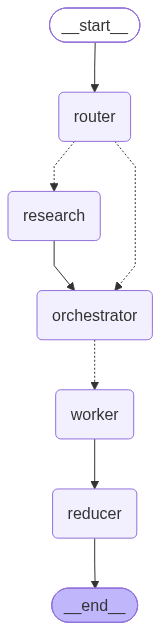

In [17]:
g = StateGraph(state)
g.add_node("router", router_node)
g.add_node("research", research)
g.add_node("orchestrator", orchestrator)
g.add_node("worker", worker)
g.add_node("reducer", reducer)

g.add_edge(START, "router")
g.add_conditional_edges("router", router_next, {"research": "research", "orchestrator": "orchestrator"})
g.add_edge("research", "orchestrator")

g.add_conditional_edges("orchestrator", fanout, ["worker"])
g.add_edge("worker", "reducer")
g.add_edge("reducer", END)

app = g.compile()
app


In [18]:
app.invoke({'topic':'write a blog on AI with hardware(IOT) and also what are the trends in 2026 and for future predictions'})

C:\Users\Tanishk\AppData\Local\Temp\ipykernel_19448\3338074035.py:2: LangChainDeprecationWarning: The class `TavilySearchResults` was deprecated in LangChain 0.3.25 and will be removed in 1.0. An updated version of the class exists in the `langchain-tavily package and should be used instead. To use it run `pip install -U `langchain-tavily` and import as `from `langchain_tavily import TavilySearch``.
  tool=TavilySearchResults(max_results=max_results)


AttributeError: 'str' object has no attribute 'get'

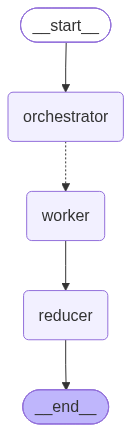

In [78]:
rs=wf.invoke({'topic':"write a blog on game theory in simpler terms for beginners"})
rs

Created: D:\AI\VS CODE\Langchain\LangGraph\Blog Planner\game_theory_for_developers_a_practical,_code-first_introduction.md


{'topic': 'write a blog on game theory in simpler terms for beginners',
 'plan': Plan(blog_title='Game Theory for Developers: A Practical, Code-First Introduction', audience='Software developers and engineers with basic math (linear algebra, probability) who want to apply game-theoretic thinking to design, algos, and product decisions', tone='Practical, concrete, and example-driven with minimal formalism', tasks=[task(id=1, title='Intro: Why game theory matters for engineers', goal='After this section the reader will be able to name three concrete engineering problems where game-theoretic thinking produces better designs and understand the framing of strategic interaction vs optimization.', bullets=['Frame a concrete problem: model ad-auction bidding, caching incentives, or distributed consensus as players, actions, and payoffs — include a 2–3 sentence formalization for one example (e.g., two bidders, bid action, utility = value - price).', "Contrast single-agent optimization vs strate